# 02 · Exploratory analysis: questions, not chart spam

Each section asks one question an engineer or buyer would ask, answers it with a statistic and one figure,
and ends with the practical takeaway. Strength statistics use only grades with a **measured** tensile strength.
Statistics come from `src/analysis/eda.py`; figures from `src/analysis/viz_eda.py`.

In [1]:
import sys, warnings
from pathlib import Path
ROOT = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()
sys.path.insert(0, str(ROOT))
warnings.filterwarnings("ignore", category=FutureWarning)

import numpy as np
import pandas as pd
from IPython.display import Image, Markdown, display

pd.set_option("display.width", 200)
pd.set_option("display.max_columns", 40)
pd.set_option("display.max_colwidth", 80)
pd.set_option("display.float_format", lambda v: f"{v:,.3f}")

from src.analysis import plotting as P
P.apply_theme()

def show(fig, name):
    path = P.save(fig, name)
    display(Image(filename=str(path)))

In [2]:
from src.analysis.cleaning import load_clean_grades
from src.analysis.constants import CLEAN_LISTINGS_CSV
from src.analysis import eda as E, viz_eda as VE
grades = load_clean_grades()
listings = pd.read_csv(CLEAN_LISTINGS_CSV)
m = E.measured(grades)
print(f"{len(grades)} grades, {len(m)} with measured tensile strength")
m[E.TS].describe()

1389 grades, 1382 with measured tensile strength


count   1,382.000
mean      651.643
std       242.454
min       140.000
25%       510.000
50%       610.000
75%       720.000
max     2,450.000
Name: tensile_strength_mpa, dtype: float64

## Q1 · How much does family alone decide strength?

,n,min,p10,p25,median,p75,p90,max,iqr
family_label,,,,,,,,,
Grey cast iron,20.000,140.000,187.000,212.500,260.000,320.000,385.000,450.000,107.500
Austenitic (Ni-Resist) cast iron,20.000,150.000,190.000,197.500,430.000,450.000,470.000,500.000,252.500
Boron steel,30.000,390.000,409.000,442.500,470.000,515.000,572.000,660.000,72.500
Fe-Ni/Co special alloy,16.000,440.000,470.000,497.500,510.000,622.500,840.000,910.000,125.000
Malleable cast iron,6.000,350.000,400.000,467.500,520.000,595.000,670.000,720.000,127.500
Carbon / non-alloy steel,196.000,290.000,380.000,440.000,525.000,620.000,710.000,810.000,180.000
Weathering steel,7.000,430.000,430.000,500.000,570.000,575.000,580.000,580.000,75.000
Alloy steel,293.000,400.000,480.000,520.000,590.000,660.000,778.000,"2,340.000",140.000
Weld metal,83.000,500.000,580.000,605.000,620.000,710.000,850.000,"1,040.000",105.000


Kruskal-Wallis across families: {'H': 430.0221, 'p_value': 0.0, 'epsilon_sq': 0.3033, 'n_families': 17}


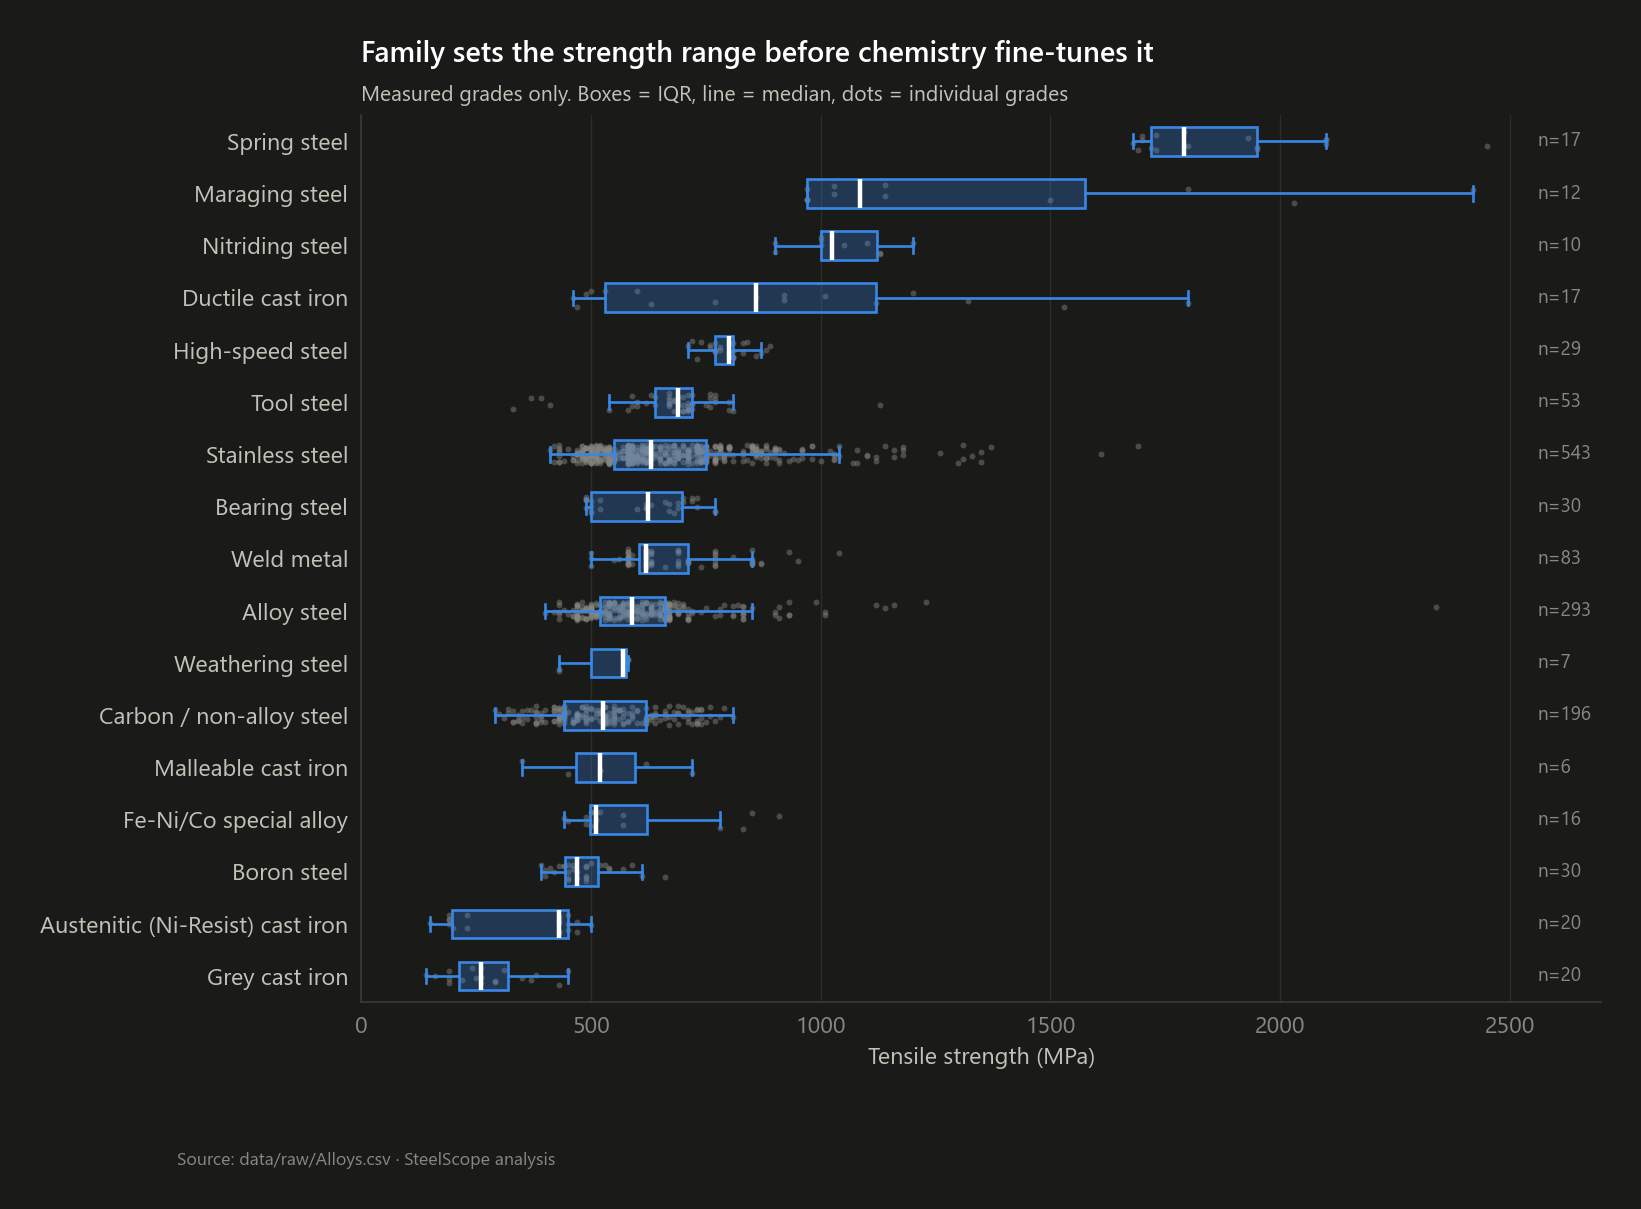

In [3]:
fam = E.family_strength_table(grades)
display(fam.set_index("family_label").drop(columns="family"))
kw = E.kruskal_family(grades)
print("Kruskal-Wallis across families:", {k: (round(v, 4) if isinstance(v, float) else v) for k, v in kw.items()})
show(VE.strength_by_family(grades), "02_strength_by_family")

**Takeaway.** Family is the first-order decision. Family medians run from grey cast iron at the bottom to spring
steel at the top, about a sevenfold spread. The Kruskal–Wallis ε² printed above is the share of the strength
*ranking* explained by family alone. Within most families the IQR is still a few hundred MPa, which is where
chemistry and processing come in. The baseline model in notebook 03 is exactly this: predict the family median.

## Q2 · Which elements drive strength, and does pooling families mislead?

In [4]:
rho, pval, sizes = E.element_correlations(grades)
print("Spearman rho with tensile strength (NaN = element essentially absent in that group)")
display(rho.round(2))
ce = E.carbon_effect(grades)
pd.Series(ce)

Spearman rho with tensile strength (NaN = element essentially absent in that group)


,All grades,Carbon & low-alloy,Stainless,Tool & high-speed,Cast irons,Weld metal
C,-0.030,0.440,0.000,0.430,0.300,0.180
Mn,-0.030,0.060,-0.010,-0.370,-0.610,0.180
Si,0.080,0.260,-0.320,0.170,0.040,-0.150
Cr,0.250,0.300,-0.120,0.450,-0.040,-0.080
Ni,0.190,0.150,-0.110,0.270,-0.020,-0.160
Mo,0.350,0.240,0.220,0.510,0.390,0.060
V,0.260,0.280,0.210,0.720,NaN,0.350
W,0.240,0.130,0.180,0.530,NaN,NaN
Co,0.180,NaN,0.020,0.690,NaN,NaN
Cu,0.120,-0.130,0.230,0.260,0.090,-0.190


rho_all                                                   -0.032
n_all                                                       1382
rho_plain                                                  0.431
n_plain                                                      574
rho_carbon_family                                          0.660
n_carbon_family                                              196
theil_sen_mpa_per_0p1C                                    47.958
theil_sen_ci_per_0p1C     (41.46341463414634, 54.54545454545455)
median_C_cast_iron                                         3.250
median_TS_cast_iron                                      430.000
dtype: object

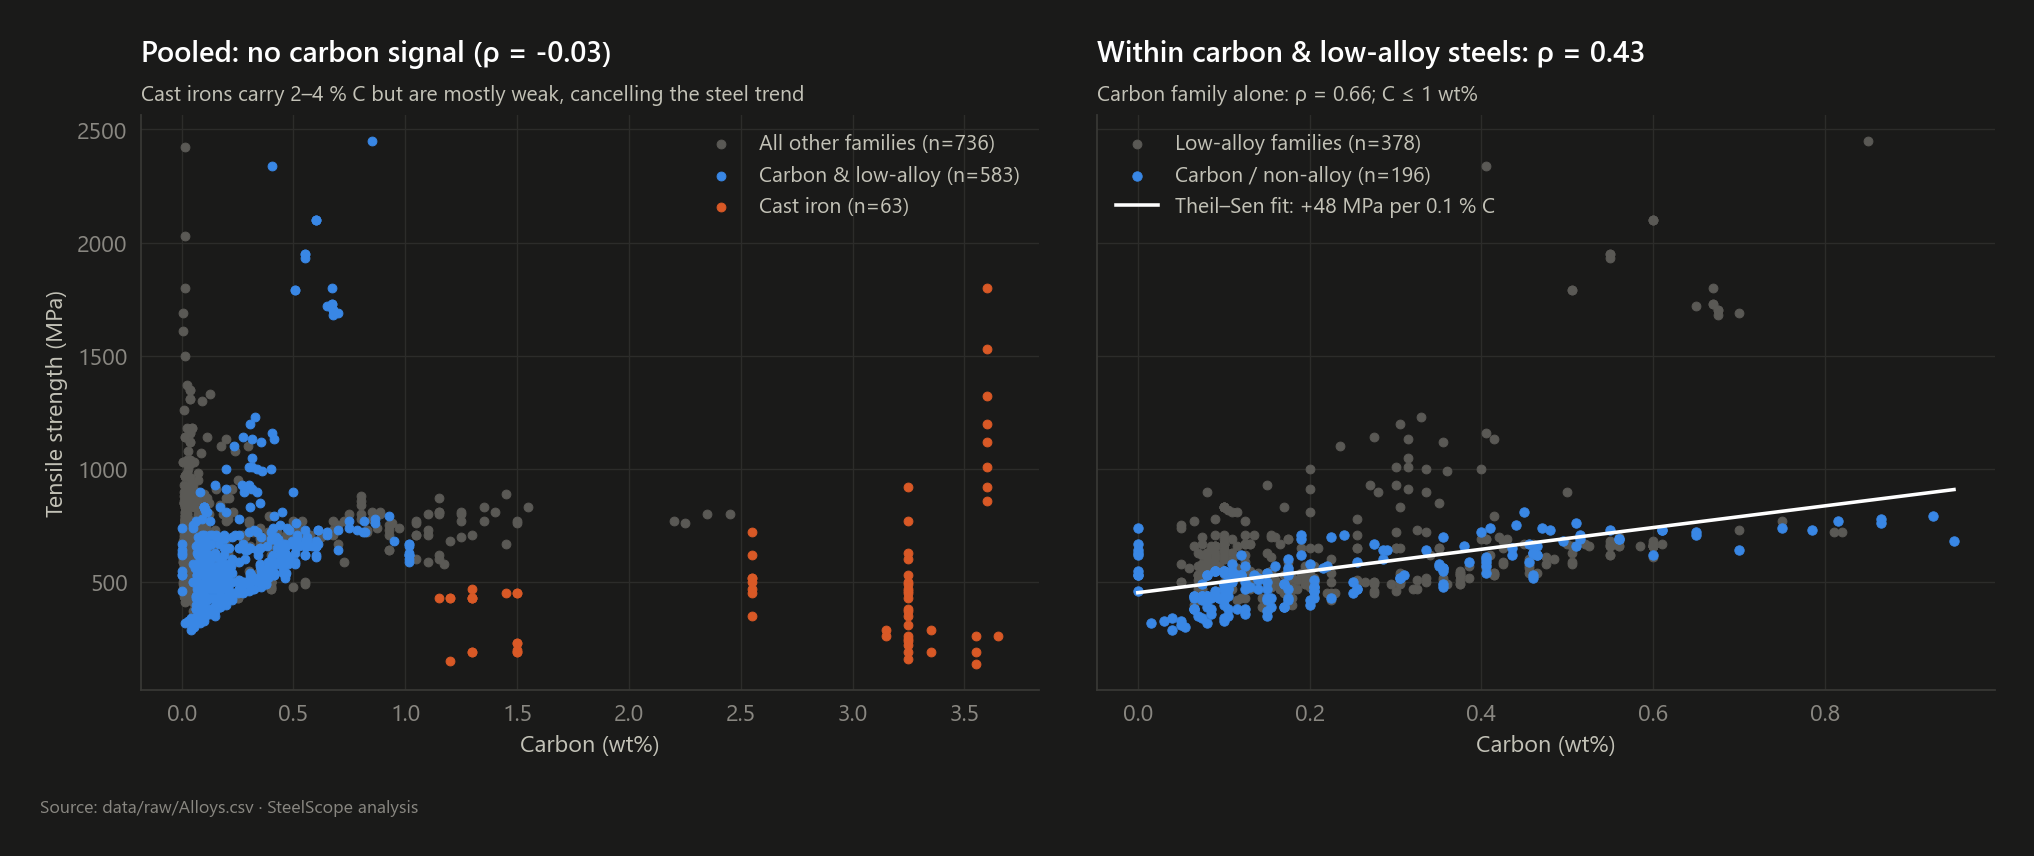

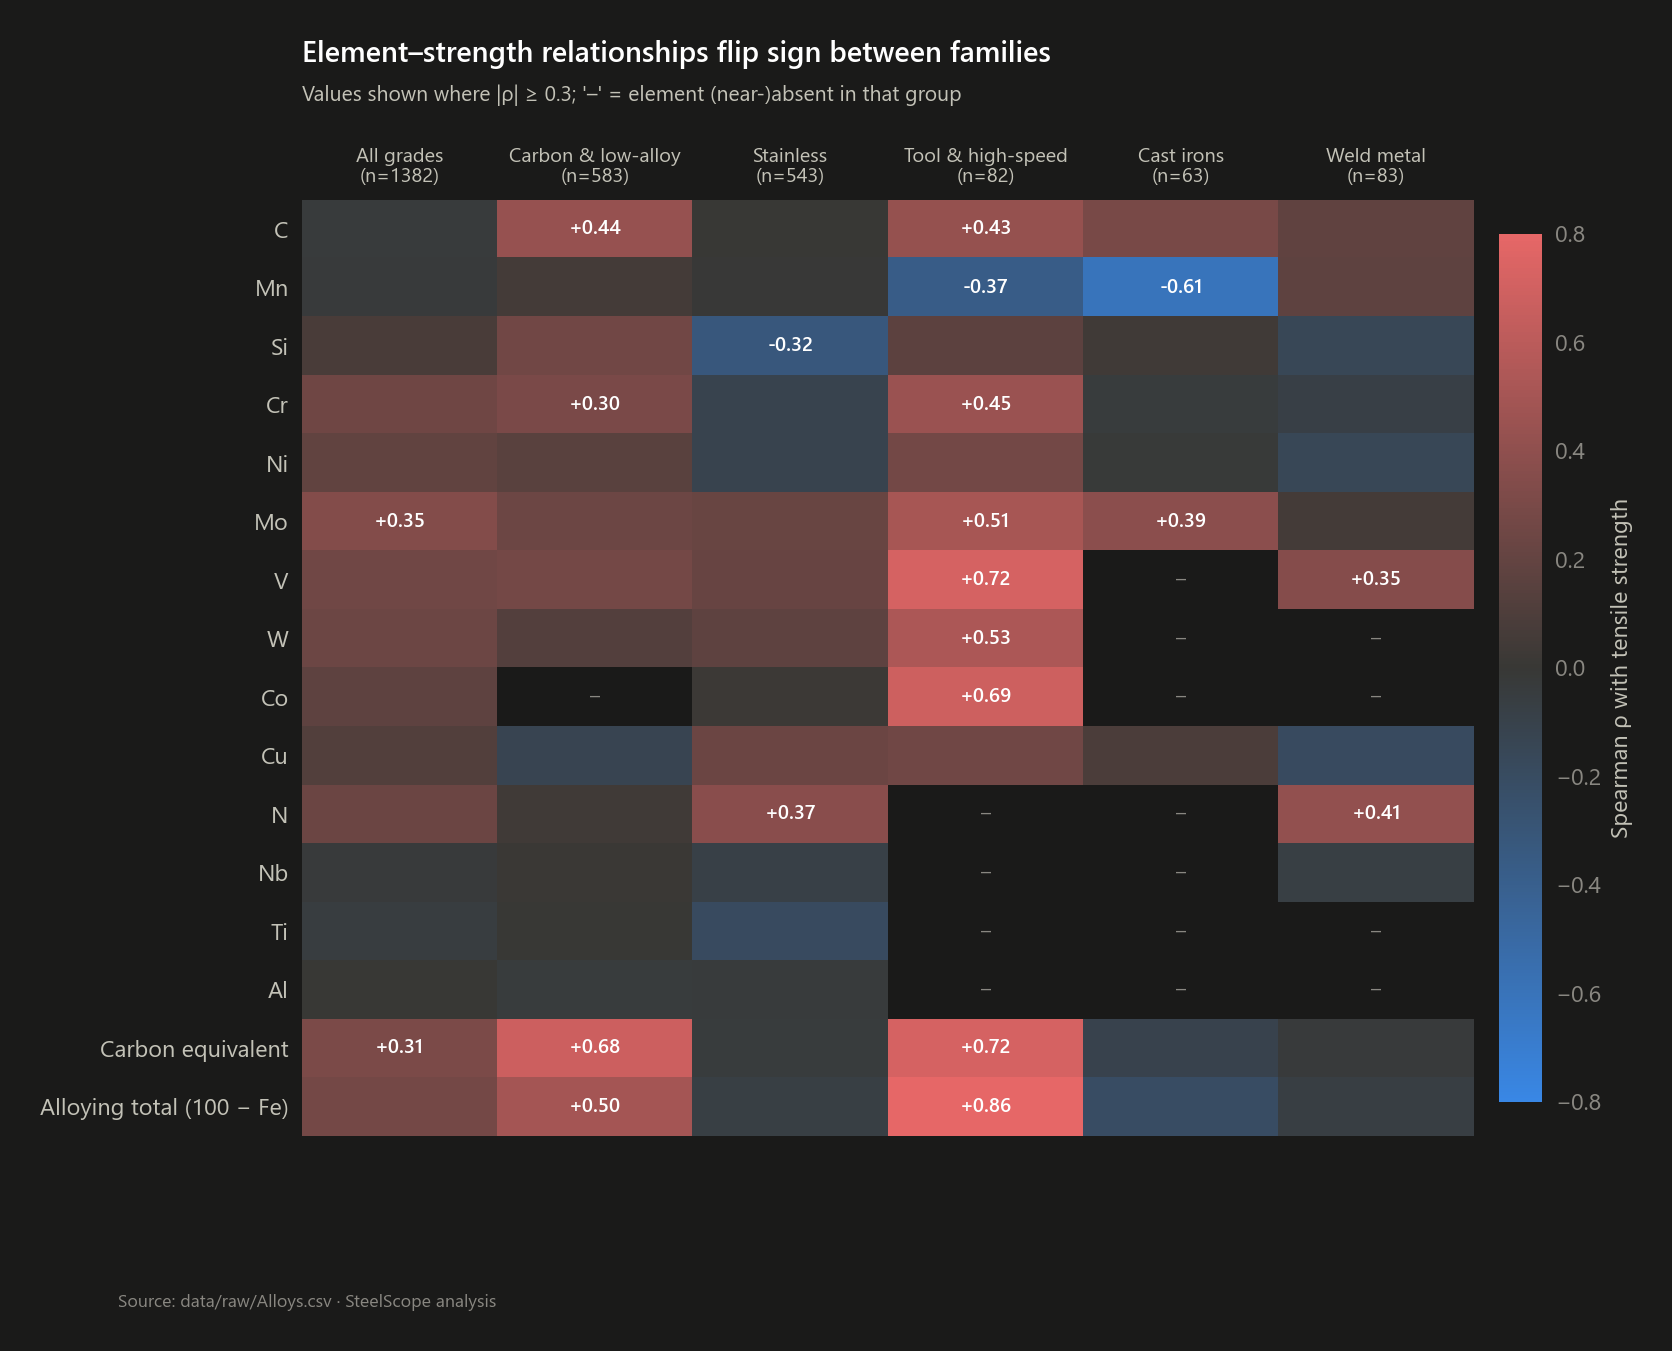

In [5]:
show(VE.carbon_paradox(grades, ce), "02_carbon_simpsons_paradox")
show(VE.correlation_heatmap(rho, sizes), "02_element_correlations")

**Takeaway.** Pooled across all grades, carbon looks irrelevant to strength. That is a **Simpson's paradox**:
cast irons hold 2–4 % carbon (as graphite) yet are mostly weak, which cancels the steel trend. Within carbon &
low-alloy steels, carbon is the dominant strengthener (Theil–Sen slope above, per 0.1 % C). The heatmap shows
the same thing for other elements: V, Co, Mo and W matter strongly in tool & high-speed steels; in stainless,
nitrogen and molybdenum help while the bulk Cr/Ni amount does not. **Any element-to-strength claim must be
made within a family.** That is also why the models include family as a feature.

## Q3 · Stainless steels: does more alloy mean more strength?

,n,median_ts,p25,p75,median_cr,median_ni,median_n,median_alloying
subgroup,,,,,,,,
Austenitic (Ni ≥ 8),255,590.000,540.000,645.000,19.000,13.500,0.015,37.800
Ferritic / martensitic (Ni < 3),159,600.000,505.000,730.000,16.000,0.250,0.000,18.500
"Duplex-type (Cr ≥ 20, Ni 3–8)",56,750.000,710.000,815.000,25.000,6.000,0.185,36.150
"Ni-bearing martensitic / PH (Ni 3–8, Cr < 20)",73,850.000,740.000,980.000,16.600,5.000,0.025,25.350


within stainless, Spearman rho(alloying_total, TS) = -0.07


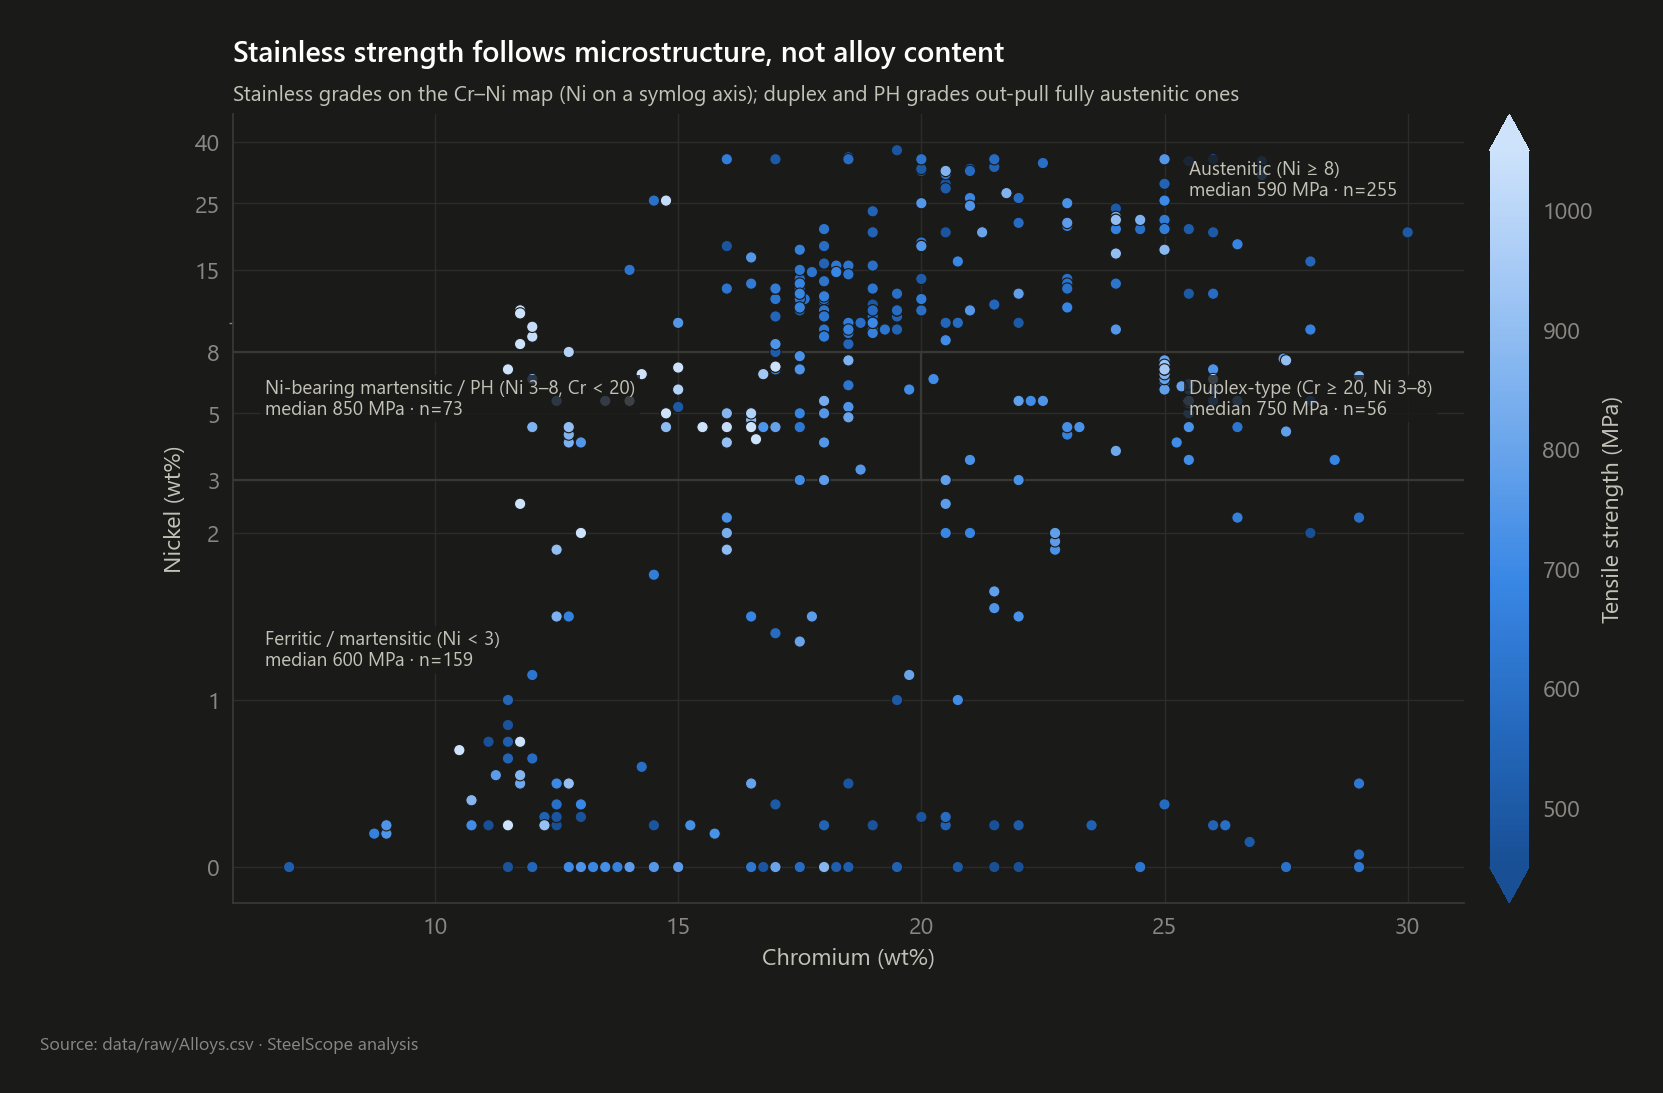

In [6]:
prof = E.stainless_profile(grades)
display(prof)
s = m[m.family == "stainless"]
from scipy import stats
print("within stainless, Spearman rho(alloying_total, TS) =", round(stats.spearmanr(s.alloying_total, s[E.TS])[0], 3))
show(VE.cr_ni_map(grades, prof), "02_cr_ni_map")

**Takeaway.** Inside the stainless family, total alloy content is essentially uncorrelated with strength.
What matters is **which microstructure** the Cr–Ni balance produces: duplex-type and Ni-bearing martensitic /
precipitation-hardening grades sit well above fully austenitic grades, despite austenitic grades carrying the
most nickel. For procurement this is the expensive mistake to avoid: a high-Ni austenitic grade is *not* the
strong option. You pay for nickel to get corrosion resistance and toughness, not strength.

## Q4 · Is carbon equivalent a useful strength index?

,n,rho_CE,p_value,median_CE
group,,,,
All grades,1382,0.312,0.000,2.487
Carbon & low-alloy,583,0.675,0.000,0.545
Stainless,543,-0.038,0.376,4.927
Tool & high-speed,82,0.723,0.000,2.066
Cast irons,63,-0.107,0.403,3.475
Weld metal,83,-0.030,0.785,4.937


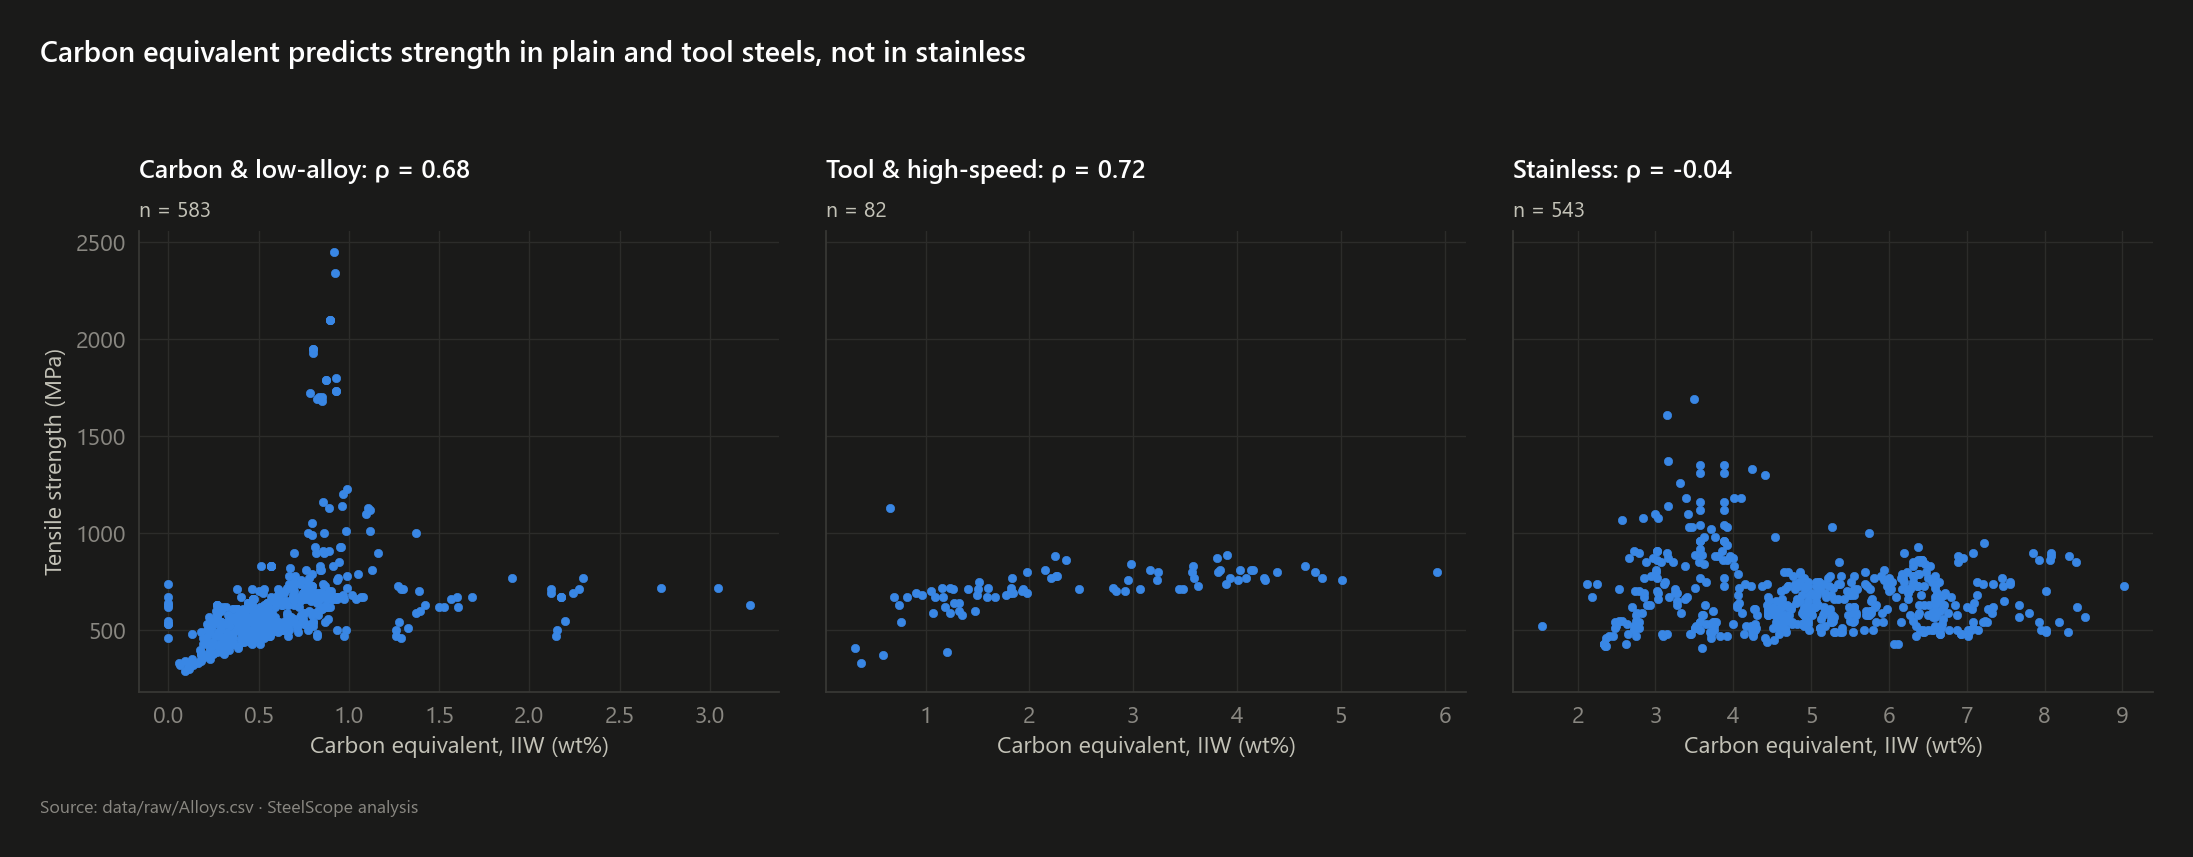

In [7]:
ce_tab = E.ce_by_group(grades)
display(ce_tab)
show(VE.ce_small_multiples(grades, ce_tab), "02_ce_vs_strength")

**Takeaway.** The IIW carbon equivalent is a decent single-number strength proxy for carbon/low-alloy and
tool steels, and meaningless for stainless (its Cr term counts corrosion-resisting chromium as if it were
hardenability) and for cast irons. Use CE to screen plain steels; do not carry it across families.

## Q5 · Strength vs liquidus: one trade-off or two independent axes?

pearson_all                        0.091
spearman_all                       0.004
n_all                               1382
pearson_non_default                0.140
spearman_non_default               0.222
n_non_default                        858
liquidus_range          (1160.0, 1830.0)
ts_range                 (140.0, 2450.0)
dtype: object

,n,ts_p10,ts_p90,liq_p10,liq_p90,share_default_liq
family_label,,,,,,
Grey cast iron,20,187.000,385.000,"1,380.000","1,390.000",0.000
Austenitic (Ni-Resist) cast iron,20,190.000,470.000,"1,340.000","1,400.000",0.000
Boron steel,30,409.000,572.000,"1,460.000","1,460.000",0.933
Weathering steel,7,430.000,580.000,"1,460.000","1,460.000",1.000
Malleable cast iron,6,400.000,670.000,"1,410.000","1,410.000",0.000
Carbon / non-alloy steel,196,380.000,710.000,"1,460.000","1,470.000",0.842
Bearing steel,30,490.000,730.000,"1,449.000","1,491.000",0.533
Tool steel,53,582.000,770.000,"1,432.000","1,628.000",0.226
Alloy steel,293,480.000,778.000,"1,460.000","1,470.000",0.744


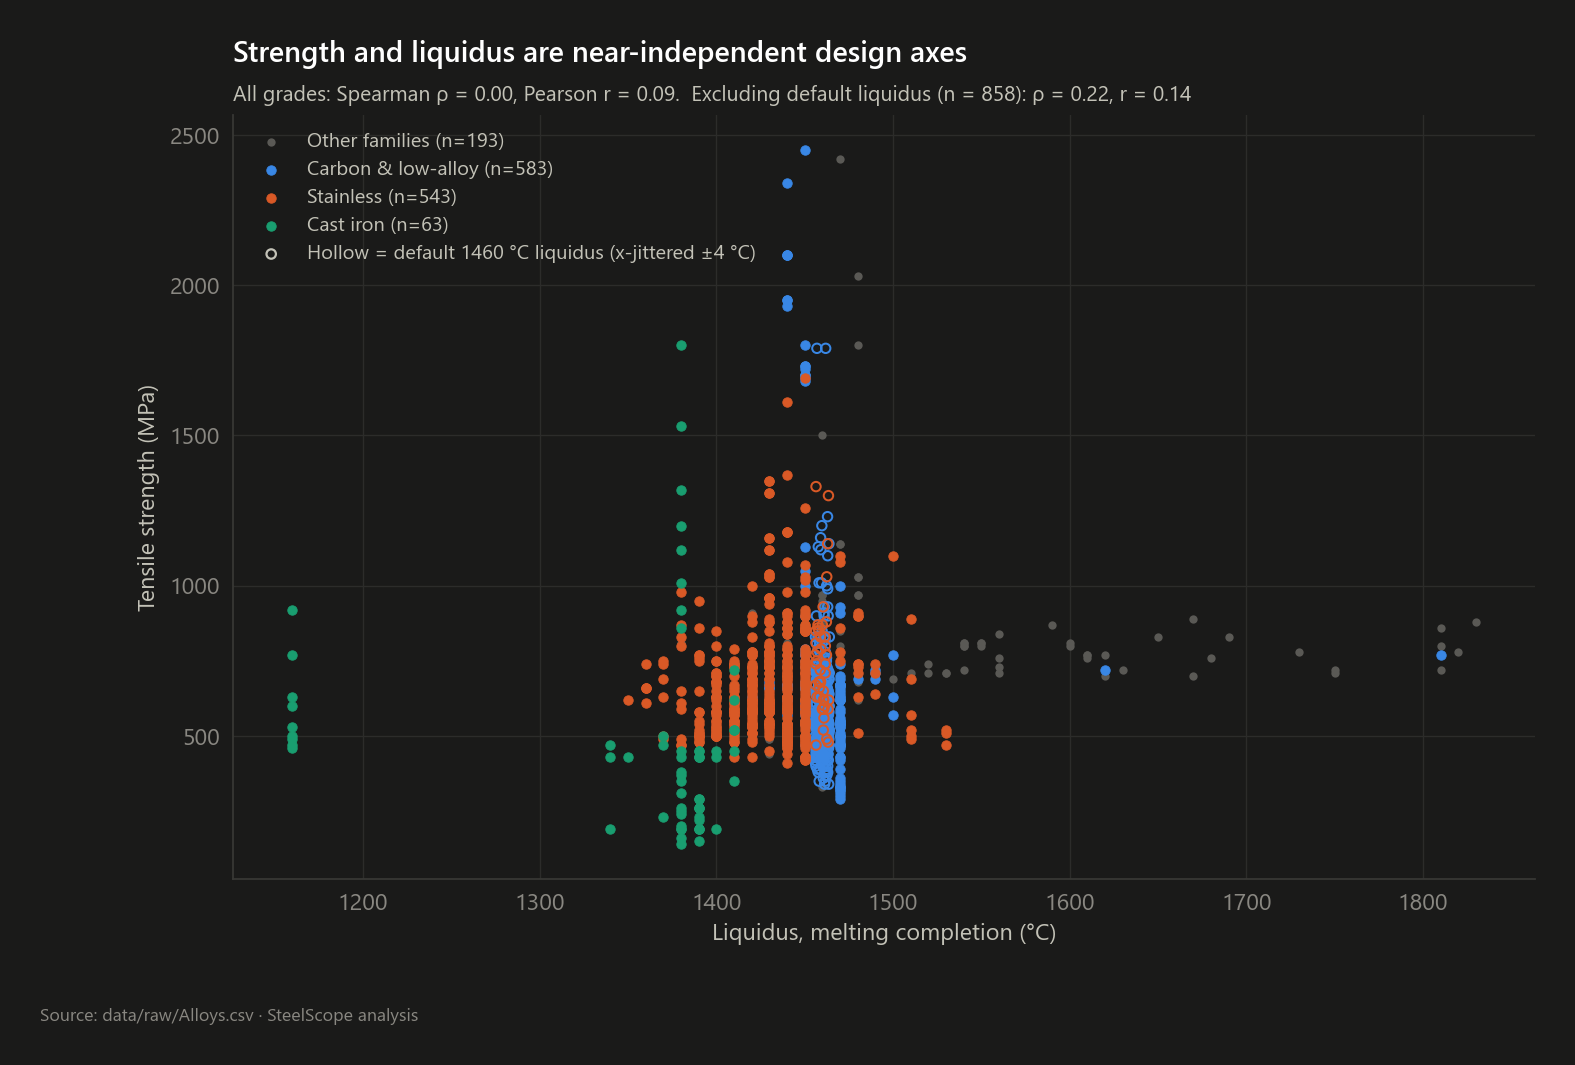

In [8]:
ds = E.design_space_stats(grades)
display(pd.Series(ds))
display(E.design_space_by_family(grades))
show(VE.design_space(grades, ds), "02_design_space")

**Takeaway.** Tensile strength and liquidus are at most weakly related: no correlation across all grades, and
only a weak one once the default 1460 °C values are removed (coefficients above). They are **near-independent
design axes**: picking a strength band barely constrains the melting range, and vice versa. That justifies the
app's Target Designer, which filters on both axes at once. Liquidus mostly separates *families* (cast irons sit
at the low end, high-speed steels at the top; see the P10–P90 table), not grades within a family.

Example query, as the Target Designer runs it: **800–1000 MPa with a liquidus of 1420–1470 °C**, with and
without the default-liquidus grades.

In [9]:
q, fam_q, env = E.target_design_query(grades, 800, 1000, 1420, 1470)
print(f"{len(q)} grades match"); display(fam_q.head(8)); display(env.round(3))
q2, fam_q2, _ = E.target_design_query(grades, 800, 1000, 1420, 1470, exclude_default_liquidus=True)
print(f"excluding default liquidus: {len(q2)} grades"); display(fam_q2.head(8))

100 grades match


,n,share
family_label,,
Stainless steel,56,0.560
Alloy steel,20,0.200
Weld metal,10,0.100
Nitriding steel,5,0.050
Fe-Ni/Co special alloy,3,0.030
Tool steel,3,0.030
Maraging steel,2,0.020
Carbon / non-alloy steel,1,0.010


,p10,p50,p90
C,0.015,0.035,0.335
Mn,0.350,0.650,1.600
Si,0.200,0.362,0.500
Cr,0.390,12.750,25.000
Ni,0.145,4.100,17.550
Mo,0.000,0.575,3.525
V,0.000,0.000,0.200
W,0.000,0.000,0.000
Co,0.000,0.000,0.000
Cu,0.000,0.100,1.775


excluding default liquidus: 61 grades


,n,share
family_label,,
Stainless steel,45,0.738
Weld metal,5,0.082
Nitriding steel,3,0.049
Fe-Ni/Co special alloy,3,0.049
Tool steel,3,0.049
Alloy steel,2,0.033


## Q6 · What separates the strength classes?

,epsilon_sq,H,p_value,median_low,median_medium,median_high,share_nonzero_low,share_nonzero_medium,share_nonzero_high
feature,,,,,,,,,
Mo,0.097,135.146,0.000,0.000,0.040,0.375,0.087,0.505,0.710
carbon_equivalent,0.063,89.555,0.000,3.533,0.750,3.070,1.000,0.994,0.993
V,0.062,86.966,0.000,0.000,0.000,0.000,0.000,0.125,0.305
N,0.052,73.779,0.000,0.000,0.000,0.000,0.000,0.230,0.385
alloying_total,0.046,65.356,0.000,7.000,3.525,17.800,1.000,1.000,1.000
Si,0.045,63.967,0.000,2.000,0.275,0.375,1.000,0.934,0.948
W,0.043,61.511,0.000,0.000,0.000,0.000,0.000,0.012,0.115
Cr,0.042,59.882,0.000,0.000,0.950,9.000,0.391,0.750,0.873
C,0.040,57.747,0.000,3.250,0.100,0.100,1.000,0.994,0.993


strength_class_label,High (>600 MPa),Low (<300 MPa),Medium (300-600 MPa)
family_label,,,
Alloy steel,136,0,157
Austenitic (Ni-Resist) cast iron,0,8,12
Bearing steel,18,0,12
Boron steel,2,0,28
Carbon / non-alloy steel,53,1,142
Ductile cast iron,11,0,6
Fe-Ni/Co special alloy,4,0,12
Grey cast iron,0,14,6
High-speed steel,29,0,0


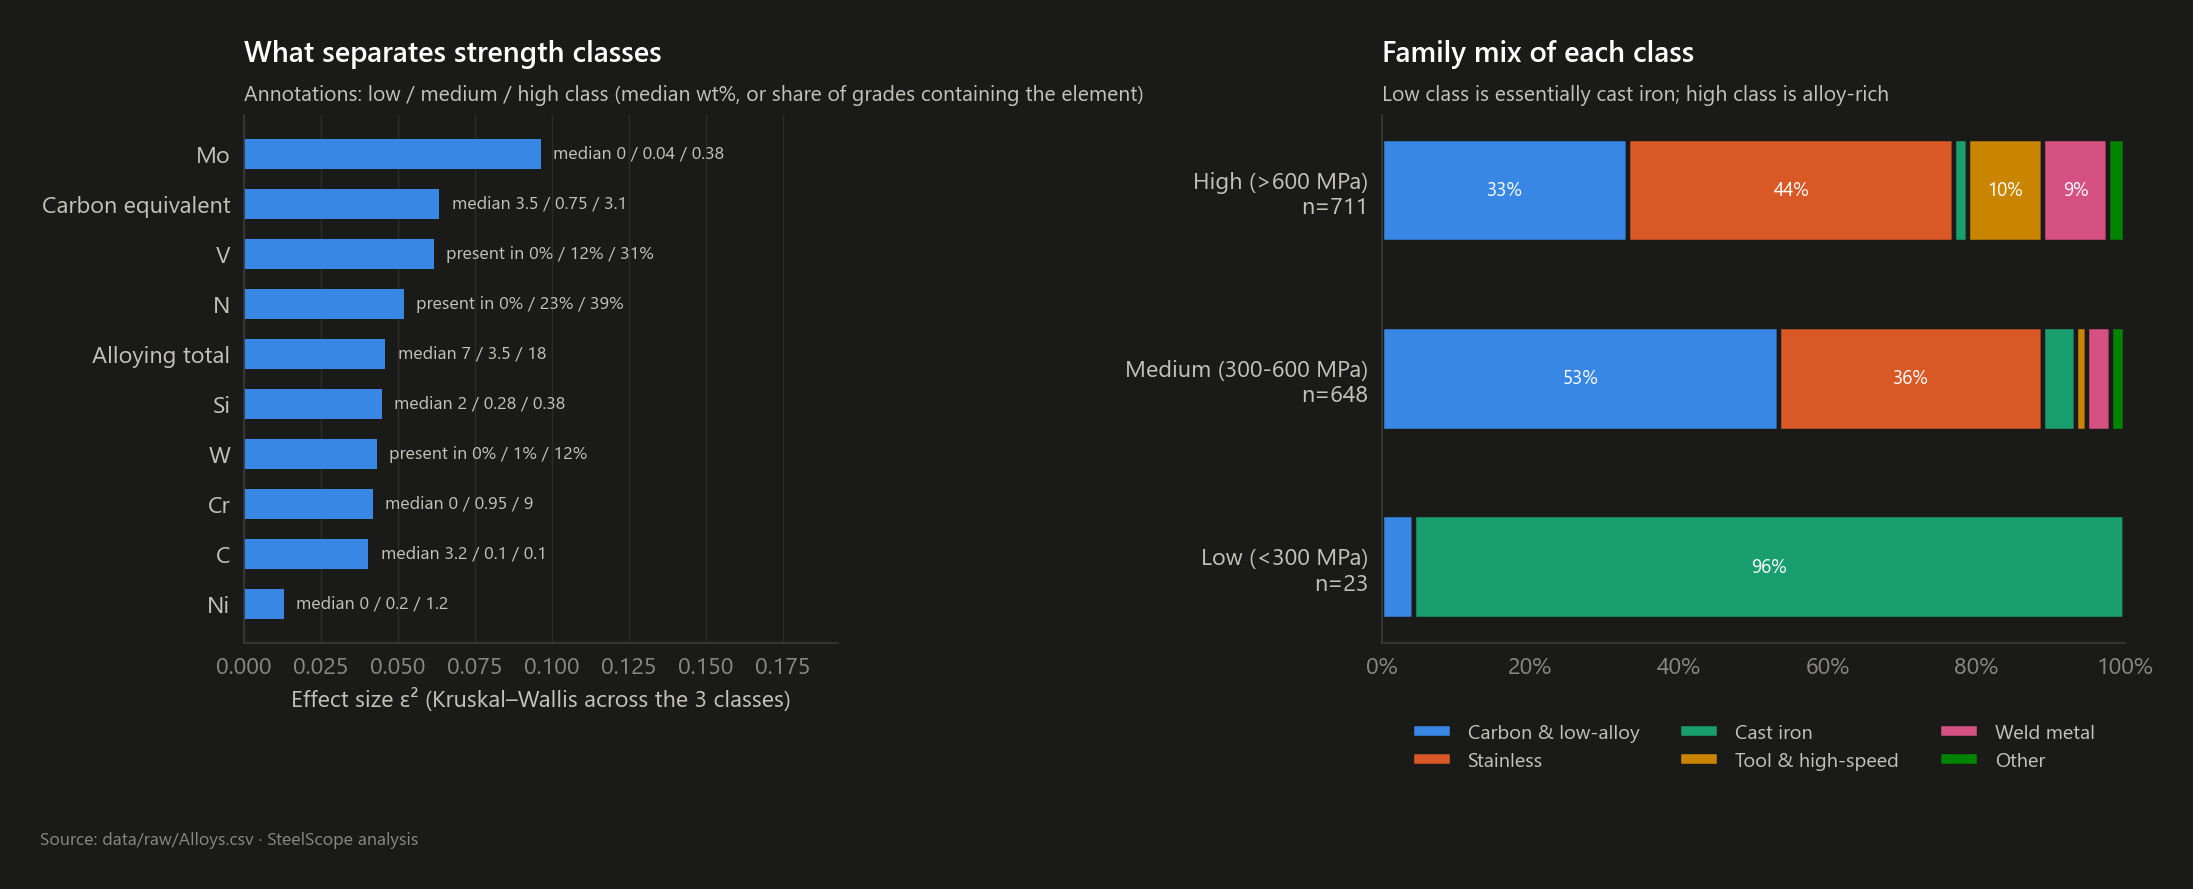

In [10]:
sep = E.class_separation(grades)
display(sep.round(3))
display(E.class_family_mix(grades))
show(VE.class_drivers(sep, grades), "02_class_drivers")

**Takeaway.** No single element separates the classes strongly: even the largest effect size (Mo) is small.
The classes are separated mainly by **family**. The low class (< 300 MPa) is almost entirely cast iron (grey
and Ni-Resist), which is why its carbon median is high. Every high-speed, maraging, spring and nitriding grade
is high-class, and the high class carries several times more alloy than the medium class (alloying-total medians
above). The low class is tiny (see n), so the classifier in notebook 03 must be class-balanced and judged on
macro-F1, not accuracy.

## Q7 · How do conclusions change with vs without the imputed rows?

scenario,A. naive rows (imputed kept),"B. rows, imputed dropped","C. grades, measured (used)"
n,"2,610.000","2,141.000","1,382.000"
ts_mean,655.465,656.119,651.643
ts_median,650.000,610.000,610.000
ts_sd,217.860,240.547,242.454
share_high_class,0.609,0.523,0.514
share_low_class,0.009,0.011,0.017
spearman_C,0.022,-0.050,-0.032
spearman_Mn,-0.039,0.008,-0.030
spearman_Cr,0.206,0.260,0.251
spearman_Ni,0.080,0.149,0.190


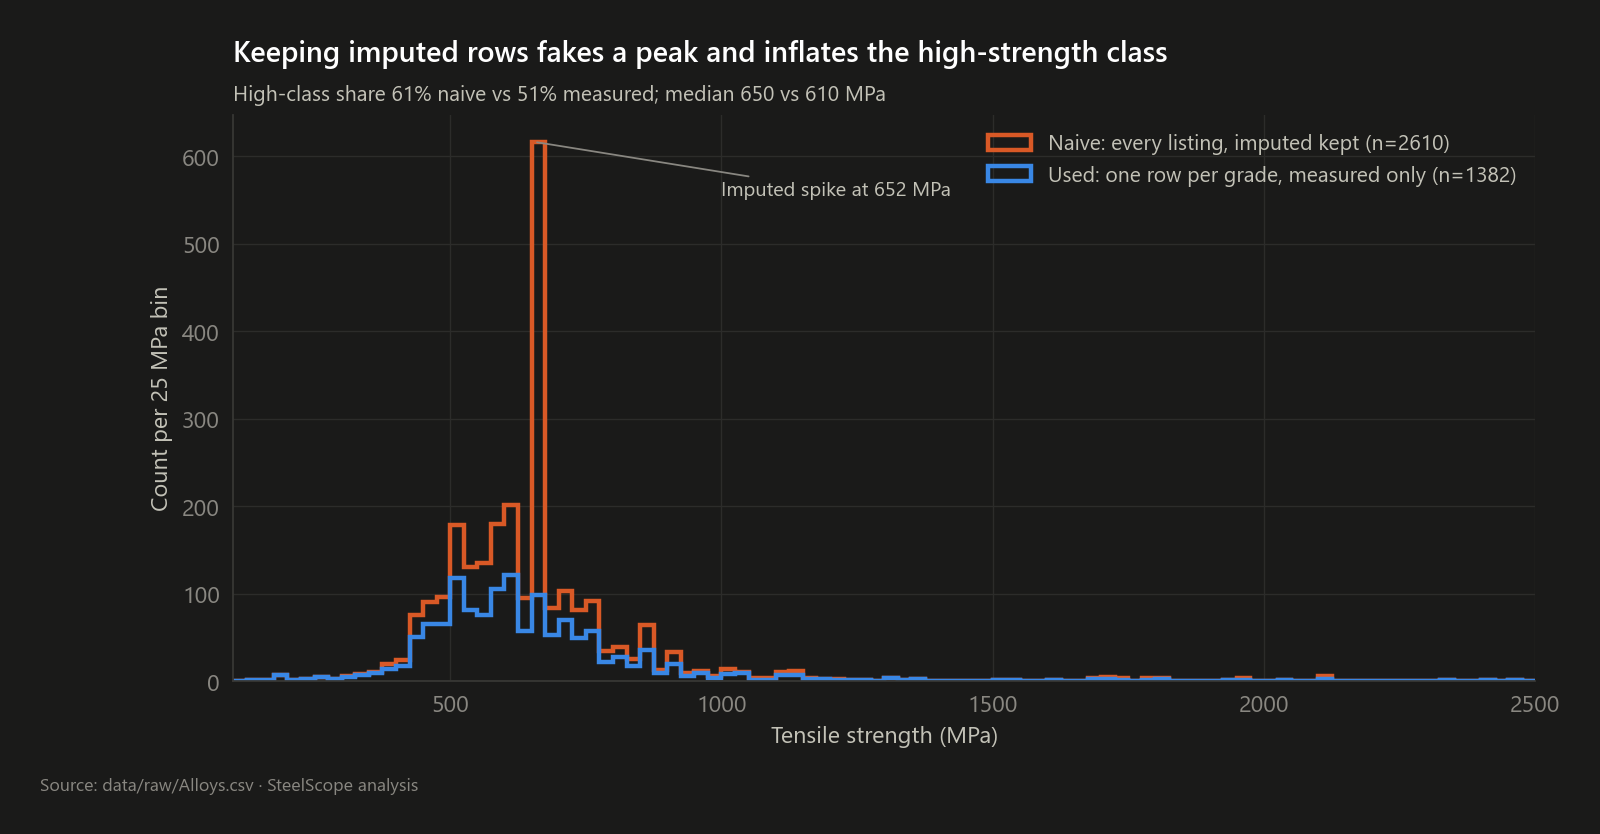

In [11]:
from src.analysis.quality import imputation_sensitivity
sens = imputation_sensitivity(listings, grades)
display(sens.T.round(3))
show(VE.imputation_sensitivity(listings, grades, sens), "02_imputation_sensitivity")

**Takeaway.** Treating the imputed constant as data would:

* create a fake mode at 652 MPa and overstate the share of high-strength grades;
* set the **median of whole families** (stainless, tool) to exactly the imputed value;
* weaken the true element–strength correlations (e.g. Ni, Mo, V), because a constant was mixed into the target.

Dropping imputed rows *but keeping twin listings* (scenario B) fixes the values, but still double-counts most
grades, so every grade listed twice gets twice the weight. Scenario C (one row per grade, measured TS) is used
everywhere else in this project.